# 29. Sentiment Analysis

## Overview
Sentiment analysis classifies text according to expressed opinion or emotional polarity. This notebook builds a reproducible baseline with TF-IDF and Logistic Regression, evaluates its predictions, and inspects model confidence.

The dataset is a small illustrative collection of labeled reviews. Its purpose is to demonstrate the workflow rather than to provide a reliable benchmark.

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score

## 2. Create a labeled review dataset

Each review has a sentiment label. Real-world systems should be trained and tested on larger, representative, carefully labeled data.

In [2]:
reviews = [
    ("Absolutely love this product, it works perfectly.", "positive"),
    ("Excellent quality and very easy to use.", "positive"),
    ("Fast delivery and helpful customer service.", "positive"),
    ("The experience was wonderful from start to finish.", "positive"),
    ("Great value for money; I would buy it again.", "positive"),
    ("The design is beautiful and the performance is impressive.", "positive"),
    ("I am very satisfied with this purchase.", "positive"),
    ("Works better than expected and feels reliable.", "positive"),
    ("The product broke after only two days.", "negative"),
    ("Very disappointing quality and terrible support.", "negative"),
    ("The service was slow and nobody helped me.", "negative"),
    ("I regret buying this; it was a waste of money.", "negative"),
    ("The device stopped working and cannot be repaired.", "negative"),
    ("Poor design, confusing setup, and bad performance.", "negative"),
    ("I am unhappy with this purchase.", "negative"),
    ("The delivery was late and the package was damaged.", "negative"),
    ("The package includes a cable and a user guide.", "neutral"),
    ("The product is available in three colors.", "neutral"),
    ("The meeting starts at nine o'clock tomorrow.", "neutral"),
    ("This model has a screen and two buttons.", "neutral"),
    ("The report contains several tables and charts.", "neutral"),
    ("The store is located near the central station.", "neutral"),
    ("The box lists the size and serial number.", "neutral"),
    ("The device was released in March.", "neutral"),
]

df = pd.DataFrame(reviews, columns=["text", "sentiment"])
display(df.head())
display(df["sentiment"].value_counts().rename("count").to_frame())

,text,sentiment
0,"Absolutely love this product, it works perfectly.",positive
1,Excellent quality and very easy to use.,positive
2,Fast delivery and helpful customer service.,positive
3,The experience was wonderful from start to fin...,positive
4,Great value for money; I would buy it again.,positive


,count
sentiment,
positive,8
negative,8
neutral,8


## 3. Split data into training and test sets

Stratification maintains approximate class proportions across the split.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"],
    df["sentiment"],
    test_size=0.30,
    random_state=42,
    stratify=df["sentiment"],
)

print("Training examples:", len(X_train))
print("Test examples:", len(X_test))

Training examples: 16
Test examples: 8


## 4. Build and train the model

The pipeline fits TF-IDF only on training text and then trains a Logistic Regression classifier.

In [4]:
sentiment_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), lowercase=True)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])

sentiment_model.fit(X_train, y_train)
print("Model training complete.")

Model training complete.


## 5. Evaluate the model

Accuracy is a useful starting point, but the classification report gives per-class precision, recall, and F1-score.

In [5]:
y_pred = sentiment_model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred, zero_division=0))

Test accuracy: 0.250
              precision    recall  f1-score   support

    negative       0.17      0.50      0.25         2
     neutral       1.00      0.33      0.50         3
    positive       0.00      0.00      0.00         3

    accuracy                           0.25         8
   macro avg       0.39      0.28      0.25         8
weighted avg       0.42      0.25      0.25         8



## 6. Visualize the confusion matrix

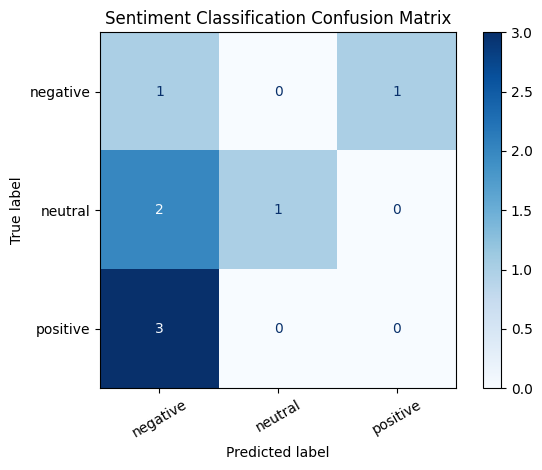

In [6]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["negative", "neutral", "positive"],
    cmap="Blues",
    xticks_rotation=30,
)
plt.title("Sentiment Classification Confusion Matrix")
plt.tight_layout()
plt.show()

## 7. Predict sentiment for new reviews

The model can return both predicted labels and class probabilities. Probabilities are model estimates and should not automatically be interpreted as calibrated confidence.

In [7]:
new_reviews = [
    "The quality is fantastic and I am very happy.",
    "The product failed and the service was awful.",
    "The package contains a charger and an instruction booklet.",
]

predicted_labels = sentiment_model.predict(new_reviews)
predicted_probabilities = sentiment_model.predict_proba(new_reviews)
classes = sentiment_model.named_steps["classifier"].classes_

for review, label, probabilities in zip(new_reviews, predicted_labels, predicted_probabilities):
    probability_by_class = dict(zip(classes, probabilities.round(3)))
    print(f"Review: {review}")
    print(f"Predicted sentiment: {label}")
    print(f"Model probabilities: {probability_by_class}")
    print()

Review: The quality is fantastic and I am very happy.
Predicted sentiment: positive
Model probabilities: {'negative': np.float64(0.343), 'neutral': np.float64(0.308), 'positive': np.float64(0.349)}

Review: The product failed and the service was awful.
Predicted sentiment: negative
Model probabilities: {'negative': np.float64(0.481), 'neutral': np.float64(0.286), 'positive': np.float64(0.233)}

Review: The package contains a charger and an instruction booklet.
Predicted sentiment: neutral
Model probabilities: {'negative': np.float64(0.372), 'neutral': np.float64(0.389), 'positive': np.float64(0.239)}



## Interpretation and limitations

- Short, synthetic examples are not representative of real user reviews.
- Sentiment can depend on sarcasm, negation, domain, and context.
- A production model needs representative data, careful validation, and ongoing monitoring.
- If the target language is Persian, use a suitable Persian dataset and language-aware preprocessing.

## Summary

This notebook demonstrates an end-to-end sentiment classification workflow with TF-IDF, Logistic Regression, evaluation metrics, a confusion matrix, and predictions on new text.